In [15]:
# Import libraries and basic setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_venn import venn3
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree
import os

In [16]:
# Configure plot style
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 8,
    'axes.labelsize': 8,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 6,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.02,
    'axes.linewidth': 0.5,
    'grid.linewidth': 0.5,
    'lines.linewidth': 1,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'axes.spines.top': True,
    'axes.spines.right': True,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})


In [17]:
# Define color schemes
color_scheme = {
    'background': '#FFFFFF',
    'unselected': '#DDDDDD',
    'top2a': '#4878D0',
    'aurkb': '#EE854A',
    'mki67': '#6ACC64',
    'top2a_aurkb': '#956CB4',
    'top2a_mki67': '#70CFDA',
    'aurkb_mki67': '#D6A158',
    'all_three': '#D65F5F'
}
color_maps = {
    "viridis": plt.cm.viridis,
    "plasma": plt.cm.plasma,
    "sunset": LinearSegmentedColormap.from_list('sunset', 
        ['#FFFFFF', '#FFF4B3', '#FFD371', '#FF9947', '#E85362', '#8E1A5C', '#4A148C']),
    "ocean": LinearSegmentedColormap.from_list('ocean', 
        ['#FFFFFF', '#DCEFFD', '#A7D0F4', '#5AA4DD', '#1A78B4', '#0A4C6E', '#002233']),
    "fire": LinearSegmentedColormap.from_list('fire', 
        ['#FFFFFF', '#FFF5DE', '#FFE3B0', '#FFB86F', '#FF7847', '#E32C1E', '#920000']),
}

In [18]:
# Load data
gene_expr = pd.read_csv('genes_normalized_matrix_plot.csv', index_col=0)
centroids = pd.read_csv('cell_centroids.csv')
centroids['cell_id'] = centroids['track_id'].str.replace('-', '.')

In [19]:
# Data merging and preprocessing
common_cells = set(centroids['cell_id']).intersection(set(gene_expr.columns))
print(f"Common cells: {len(common_cells)}")

centroids_filtered = centroids[centroids['cell_id'].isin(common_cells)].copy()
gene_expr_filtered = gene_expr[list(common_cells)]

Common cells: 20819


In [20]:
# Analyze gene expression patterns
target_genes = ['Top2a', 'Aurkb', 'Mki67']
gene_positive_cells = {}

for gene in target_genes:
    if gene in gene_expr.index:
        positive_cells = centroids_filtered[
            gene_expr_filtered.loc[gene, centroids_filtered['cell_id']].values > 0
        ]['track_id'].tolist()
        gene_positive_cells[gene] = positive_cells
        print(f"{gene}: {len(positive_cells)} positive cells")

Top2a: 530 positive cells
Aurkb: 234 positive cells
Mki67: 619 positive cells


In [21]:
# Cell classification
centroids_filtered['cell_type'] = 'unselected'

for idx, row in centroids_filtered.iterrows():
    cell_id = row['cell_id']
    top2a_pos = gene_expr_filtered.loc['Top2a', cell_id] > 0 if 'Top2a' in gene_expr.index else False
    aurkb_pos = gene_expr_filtered.loc['Aurkb', cell_id] > 0 if 'Aurkb' in gene_expr.index else False
    mki67_pos = gene_expr_filtered.loc['Mki67', cell_id] > 0 if 'Mki67' in gene_expr.index else False
    
    if top2a_pos and aurkb_pos and mki67_pos:
        centroids_filtered.at[idx, 'cell_type'] = 'all_three'
    elif top2a_pos and aurkb_pos:
        centroids_filtered.at[idx, 'cell_type'] = 'top2a_aurkb'
    elif top2a_pos and mki67_pos:
        centroids_filtered.at[idx, 'cell_type'] = 'top2a_mki67'
    elif aurkb_pos and mki67_pos:
        centroids_filtered.at[idx, 'cell_type'] = 'aurkb_mki67'
    elif top2a_pos:
        centroids_filtered.at[idx, 'cell_type'] = 'top2a'
    elif aurkb_pos:
        centroids_filtered.at[idx, 'cell_type'] = 'aurkb'
    elif mki67_pos:
        centroids_filtered.at[idx, 'cell_type'] = 'mki67'

type_counts = centroids_filtered['cell_type'].value_counts()
print("\nCell type statistics:")
for ct in ['top2a', 'aurkb', 'mki67', 'top2a_aurkb', 'top2a_mki67', 'aurkb_mki67', 'all_three']:
    print(f"{ct}: {type_counts.get(ct, 0)} cells")


Cell type statistics:
top2a: 446 cells
aurkb: 174 cells
mki67: 520 cells
top2a_aurkb: 16 cells
top2a_mki67: 55 cells
aurkb_mki67: 31 cells
all_three: 13 cells


In [22]:
# Save cell combination IDs
cell_combinations = {
    'Top2a_only': centroids_filtered[centroids_filtered['cell_type'] == 'top2a']['track_id'].tolist(),
    'Aurkb_only': centroids_filtered[centroids_filtered['cell_type'] == 'aurkb']['track_id'].tolist(),
    'Mki67_only': centroids_filtered[centroids_filtered['cell_type'] == 'mki67']['track_id'].tolist(),
    'Top2a+Aurkb': centroids_filtered[centroids_filtered['cell_type'] == 'top2a_aurkb']['track_id'].tolist(),
    'Top2a+Mki67': centroids_filtered[centroids_filtered['cell_type'] == 'top2a_mki67']['track_id'].tolist(),
    'Aurkb+Mki67': centroids_filtered[centroids_filtered['cell_type'] == 'aurkb_mki67']['track_id'].tolist(),
    'Top2a+Aurkb+Mki67': centroids_filtered[centroids_filtered['cell_type'] == 'all_three']['track_id'].tolist()
}

max_len = max(len(cell_combinations[key]) for key in cell_combinations)
for key in cell_combinations:
    cell_combinations[key] = cell_combinations[key] + [''] * (max_len - len(cell_combinations[key]))

combinations_df = pd.DataFrame(cell_combinations)
combinations_df.to_csv('gene_combinations_cells.csv', index=False)

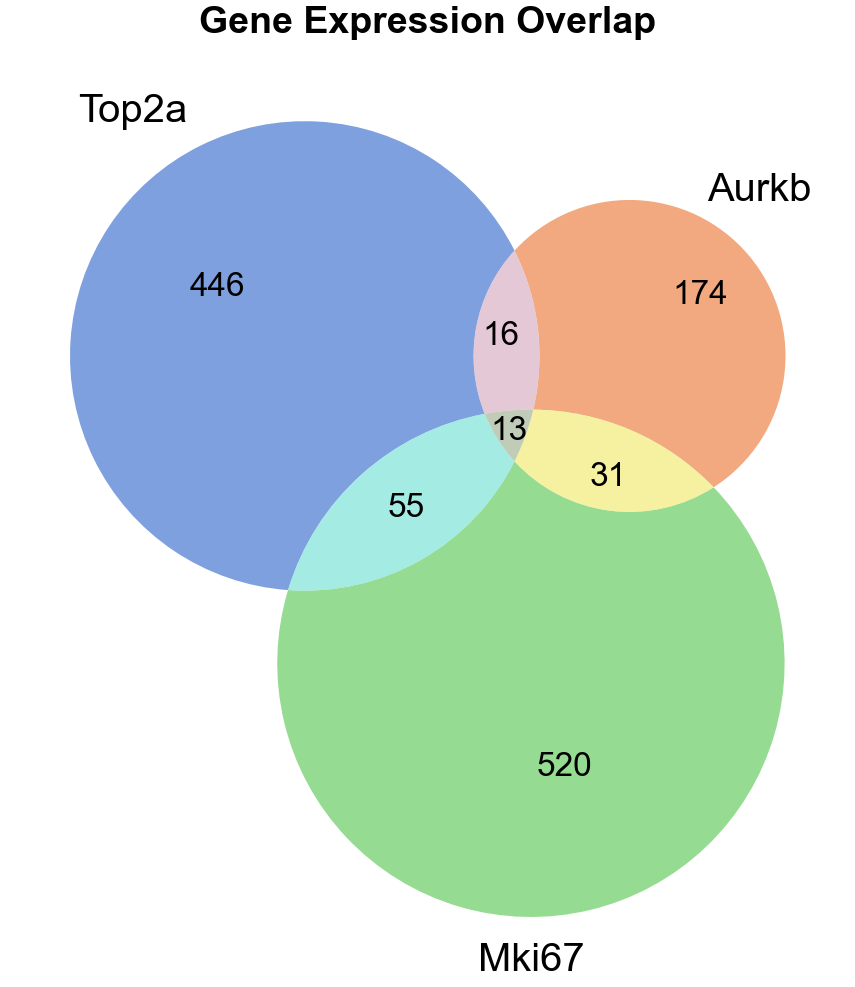

In [23]:
# Plot Venn diagram
fig_venn = plt.figure(figsize=(3.5, 3.5))

sets = [
    set(gene_positive_cells['Top2a']), 
    set(gene_positive_cells['Aurkb']), 
    set(gene_positive_cells['Mki67'])
]

venn_colors = ['#4878D0', '#EE854A', '#6ACC64']
venn = venn3(sets, ('Top2a', 'Aurkb', 'Mki67'), set_colors=venn_colors, alpha=0.7)

plt.title('Gene Expression Overlap', fontsize=9, fontweight='bold')
fig_venn.tight_layout()
fig_venn.savefig('gene_expression_venn.pdf', dpi=300, bbox_inches='tight')

plt.show()  

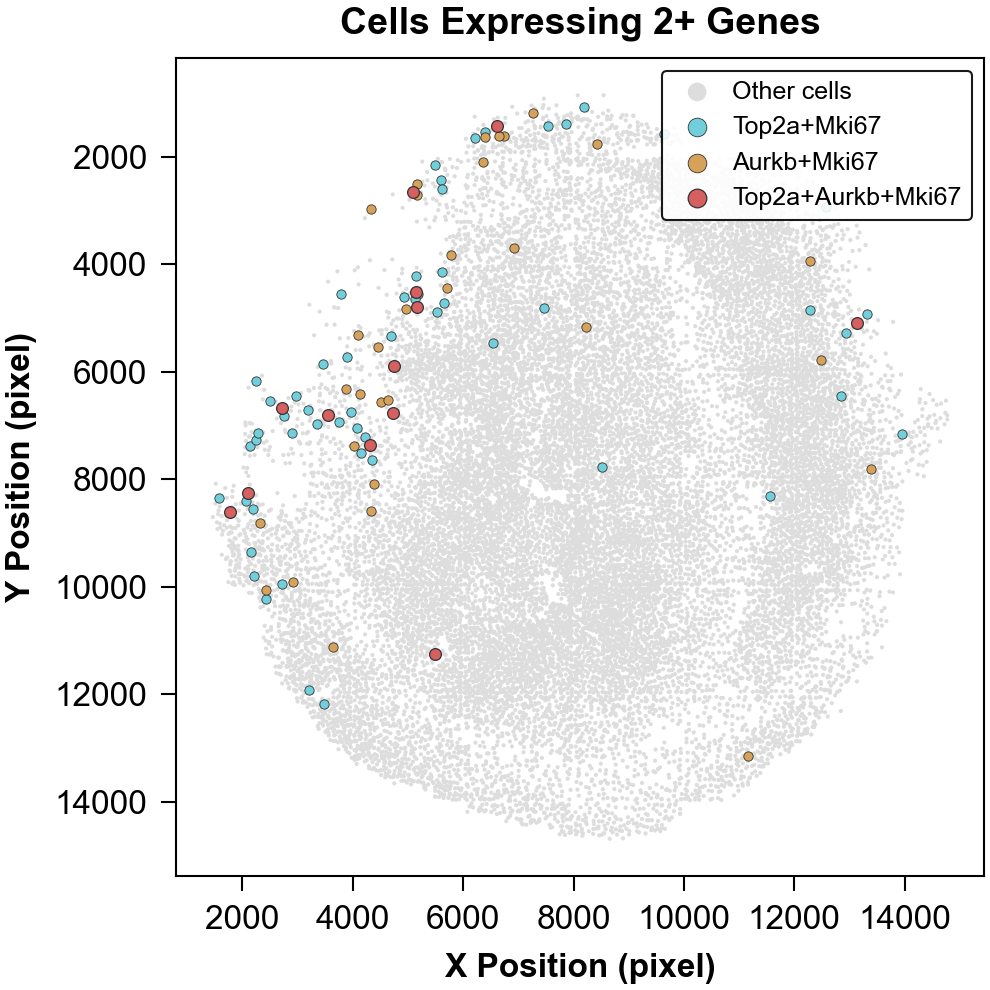

In [26]:
# Plot spatial distribution of cells expressing 2+ genes
fig_multi, ax_multi = plt.subplots(figsize=(3.5, 3.5))

multi_gene_types = ['top2a_aurkb', 'top2a_mki67', 'aurkb_mki67', 'all_three']
multi_gene_labels = {
    'top2a_aurkb': 'Top2a+Aurkb',
    'top2a_mki67': 'Top2a+Mki67',
    'aurkb_mki67': 'Aurkb+Mki67',
    'all_three': 'Top2a+Aurkb+Mki67'
}

ax_multi.scatter(
    centroids_filtered['centroid_x'],
    centroids_filtered['centroid_y'],
    c='#DDDDDD', s=1, alpha=1.0,
    edgecolors='none', label='Other cells'
)

for cell_type, color_key in [
    ('top2a_mki67', 'top2a_mki67'),
    ('aurkb_mki67', 'aurkb_mki67'),
    ('all_three', 'all_three')
]:
    cells = centroids_filtered[centroids_filtered['cell_type'] == cell_type]
    if not cells.empty:
        point_size = 8 if cell_type == 'all_three' else 5
        linewidth = 0.3 if cell_type == 'all_three' else 0.2

        ax_multi.scatter(
            cells['centroid_x'], cells['centroid_y'],
            c=color_scheme[color_key], s=point_size, alpha=1.0,
            edgecolors='#333333', linewidths=linewidth,
            label=multi_gene_labels[cell_type]
        )

ax_multi.set_xlabel('X Position (pixel)', fontweight='bold')
ax_multi.set_ylabel('Y Position (pixel)', fontweight='bold')
ax_multi.set_title('Cells Expressing 2+ Genes', fontweight='bold')

ax_multi.invert_yaxis()

legend = ax_multi.legend(
    loc='upper right', frameon=True,
    framealpha=0.9, edgecolor='black', facecolor='white',
    fontsize=6, handletextpad=0.4
)
legend.get_frame().set_linewidth(0.5)

for handle in legend.legendHandles:
    handle._sizes = [20]

x_min, x_max = centroids_filtered['centroid_x'].min(), centroids_filtered['centroid_x'].max()
y_min, y_max = centroids_filtered['centroid_y'].min(), centroids_filtered['centroid_y'].max()
x_margin = (x_max - x_min) * 0.05
y_margin = (y_max - y_min) * 0.05
ax_multi.set_xlim(x_min - x_margin, x_max + x_margin)
ax_multi.set_ylim(y_max + y_margin, y_min - y_margin)

fig_multi.tight_layout()
fig_multi.savefig('cells_2plus_genes.pdf', dpi=300, bbox_inches='tight')
plt.show()

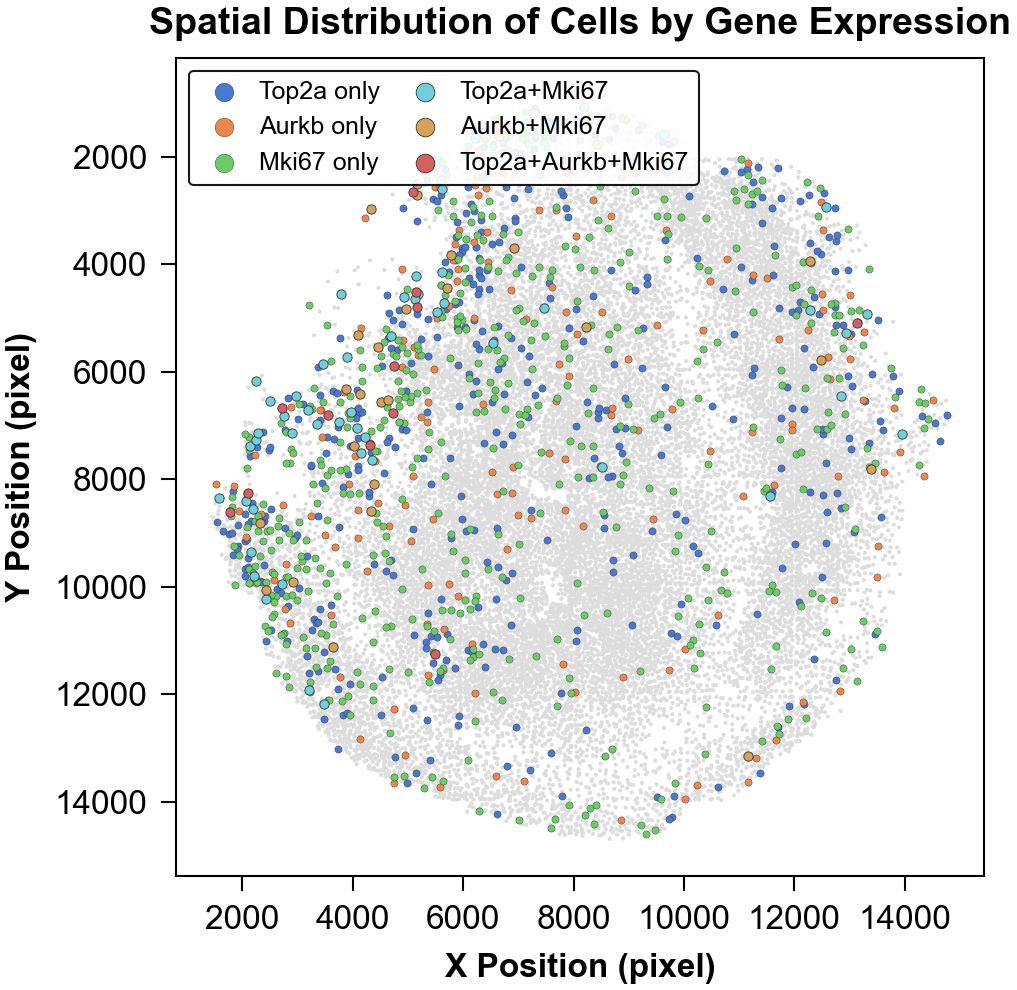

In [28]:
# Plot spatial distribution of all cell types
fig_spatial, ax_spatial = plt.subplots(figsize=(3.5, 3.5))

cell_type_labels = {
    'unselected': 'Other cells',
    'top2a': 'Top2a only',
    'aurkb': 'Aurkb only',
    'mki67': 'Mki67 only',
    'top2a_mki67': 'Top2a+Mki67',
    'aurkb_mki67': 'Aurkb+Mki67',
    'all_three': 'Top2a+Aurkb+Mki67'
}

ax_spatial.scatter(centroids_filtered[centroids_filtered['cell_type'] == 'unselected']['centroid_x'], 
           centroids_filtered[centroids_filtered['cell_type'] == 'unselected']['centroid_y'],
           c=color_scheme['unselected'], s=1, alpha=1.0, 
           edgecolors='none')

for cell_type, color_key in [
    ('top2a', 'top2a'), 
    ('aurkb', 'aurkb'), 
    ('mki67', 'mki67')
]:
    cells = centroids_filtered[centroids_filtered['cell_type'] == cell_type]
    if not cells.empty:
        ax_spatial.scatter(cells['centroid_x'], cells['centroid_y'], 
                   c=color_scheme[color_key], s=3, alpha=1.0, 
                   edgecolors='#333333', linewidths=0.1,
                   label=cell_type_labels[cell_type])

for cell_type, color_key in [
    ('top2a_mki67', 'top2a_mki67'),
    ('aurkb_mki67', 'aurkb_mki67'),
    ('all_three', 'all_three')
]:
    cells = centroids_filtered[centroids_filtered['cell_type'] == cell_type]
    if not cells.empty:
        ax_spatial.scatter(cells['centroid_x'], cells['centroid_y'], 
                   c=color_scheme[color_key], s=5, alpha=1.0, 
                   edgecolors='#333333', linewidths=0.2,
                   label=cell_type_labels[cell_type])

ax_spatial.set_xlabel('X Position (pixel)', fontweight='bold')
ax_spatial.set_ylabel('Y Position (pixel)', fontweight='bold')
ax_spatial.set_title('Spatial Distribution of Cells by Gene Expression', fontweight='bold')

ax_spatial.invert_yaxis()

legend = ax_spatial.legend(loc='upper left', frameon=True, 
                   framealpha=0.9, edgecolor='black', facecolor='white',
                   ncol=2, columnspacing=0.8, handletextpad=0.4)
legend.get_frame().set_linewidth(0.5)

for handle in legend.legendHandles:
    handle._sizes = [20]

ax_spatial.set_xlim(x_min - x_margin, x_max + x_margin)
ax_spatial.set_ylim(y_max + y_margin, y_min - y_margin)

fig_spatial.tight_layout()
fig_spatial.savefig('cell_spatial_distribution.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [31]:
# Define enhanced gene expression visualization function
def plot_gene_expression_enhanced(gene_name, centroids_data, gene_data, 
                                  output_dir="gene_plots", cmap_name="sunset", 
                                  highlight_top_pct=5):
    
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    if gene_name not in gene_data.index:
        print(f"Gene {gene_name} not found")
        return False
    
    output_file = os.path.join(output_dir, f"{gene_name}_enhanced.pdf")
    
    plot_data = centroids_data.copy()
    plot_data['expression'] = gene_data.loc[gene_name, plot_data['cell_id']].values
    
    if plot_data['expression'].isna().all():
        print(f"Gene {gene_name} has no valid expression values")
        return False
    
    cmap = color_maps.get(cmap_name, plt.cm.viridis)
    
    fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
    
    max_expr = plot_data['expression'].max()
    min_expr = plot_data['expression'].min()
    
    plot_data = plot_data.sort_values(by='expression')
    
    scatter = ax.scatter(
        x=plot_data['centroid_x'],
        y=plot_data['centroid_y'],
        c=plot_data['expression'],
        cmap=cmap,
        s=3,
        edgecolors='none',
        alpha=0.9
    )
    
    if highlight_top_pct > 0:
        threshold = np.percentile(plot_data['expression'].dropna(), 100 - highlight_top_pct)
        top_cells = plot_data[(plot_data['expression'] >= threshold) & (plot_data['expression'] > 0)]
        
        if len(top_cells) > 0:
            ax.scatter(
                x=top_cells['centroid_x'],
                y=top_cells['centroid_y'],
                s=3,
                facecolors='none',
                edgecolors='black',
                linewidths=0.5,
                alpha=0.7
            )
    
    cbar = plt.colorbar(scatter, ax=ax, shrink=0.7)
    cbar.set_label(f"{gene_name} expression", fontsize=10)
    
    ax.set_xlabel('X Coordinate', fontsize=10)
    ax.set_ylabel('Y Coordinate', fontsize=10)
    ax.set_title(f"{gene_name} Expression Pattern", fontsize=14, fontweight='bold')
    
    stats_text = f"Max: {max_expr:.2f}, Min: {min_expr:.2f}"
    ax.text(0.02, 0.02, stats_text, transform=ax.transAxes, 
            fontsize=8, va='bottom', ha='left',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
    
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    
    ax.invert_yaxis()
    
    plt.tight_layout()
    plt.savefig(output_file, format='pdf', bbox_inches='tight')
    plt.show()
    print(f"Saved to {output_file}")
    return True


Plotting gene expression maps...


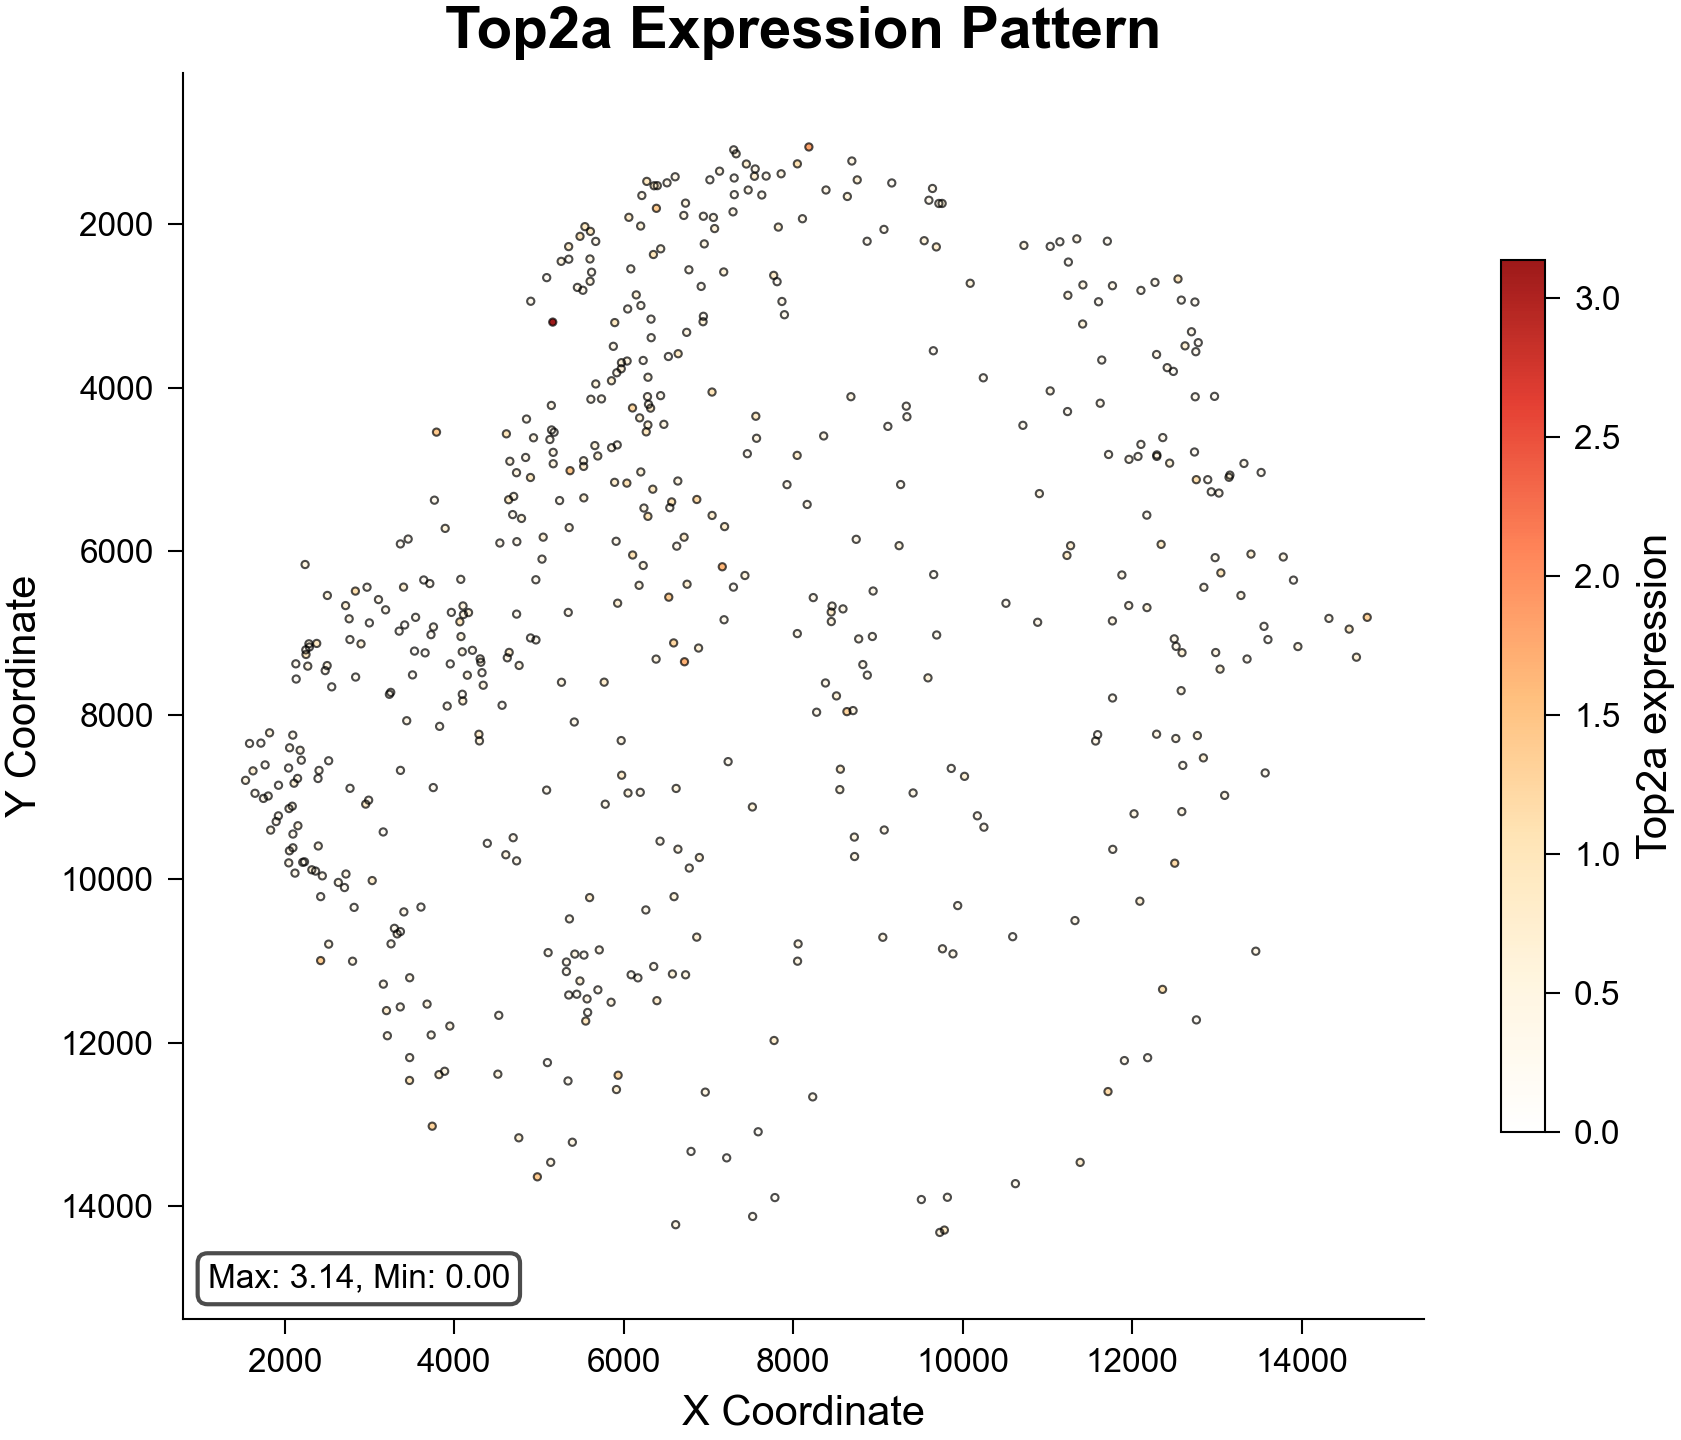

Saved to gene_plots/Top2a_enhanced.pdf


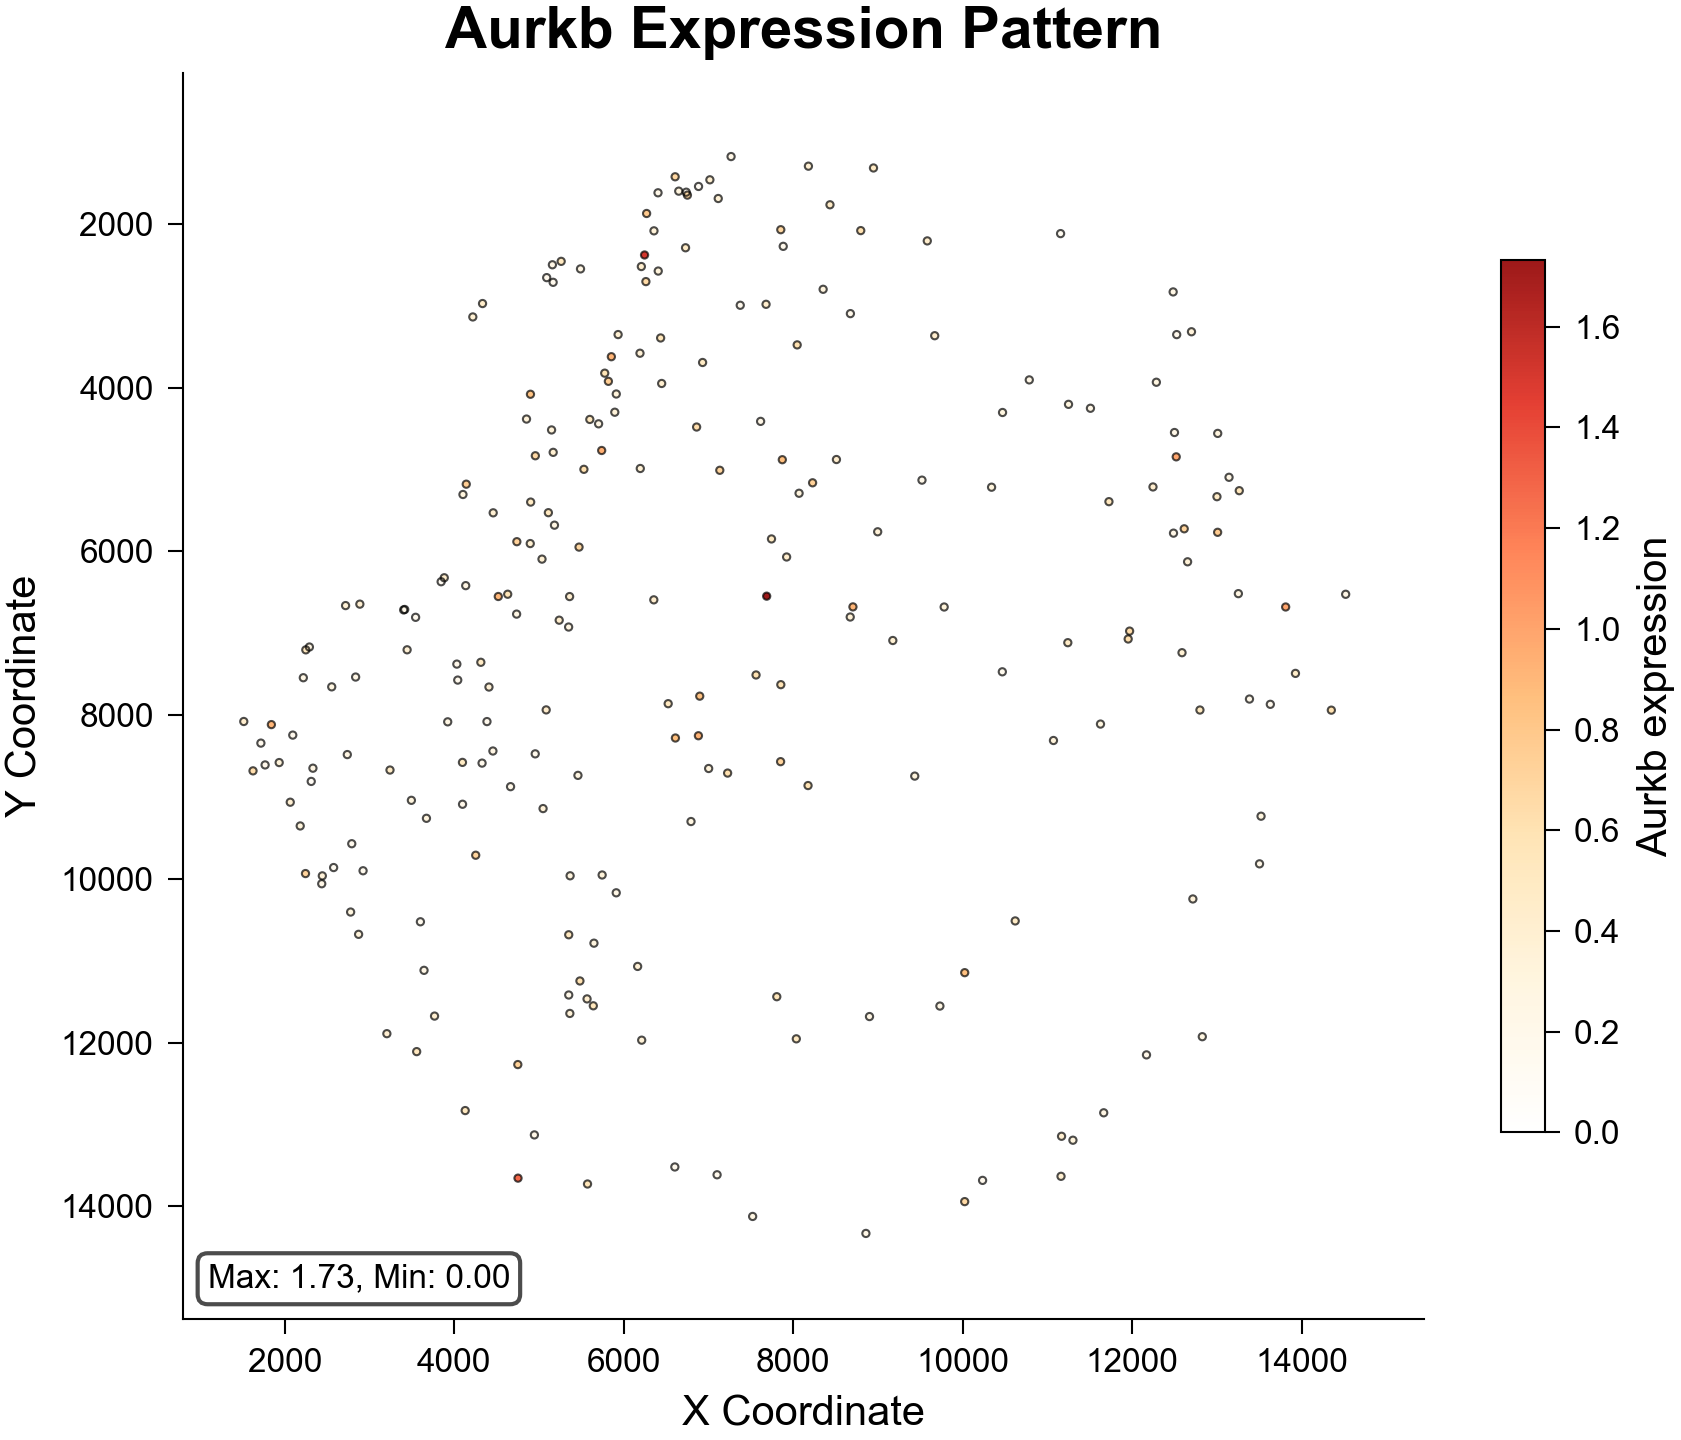

Saved to gene_plots/Aurkb_enhanced.pdf


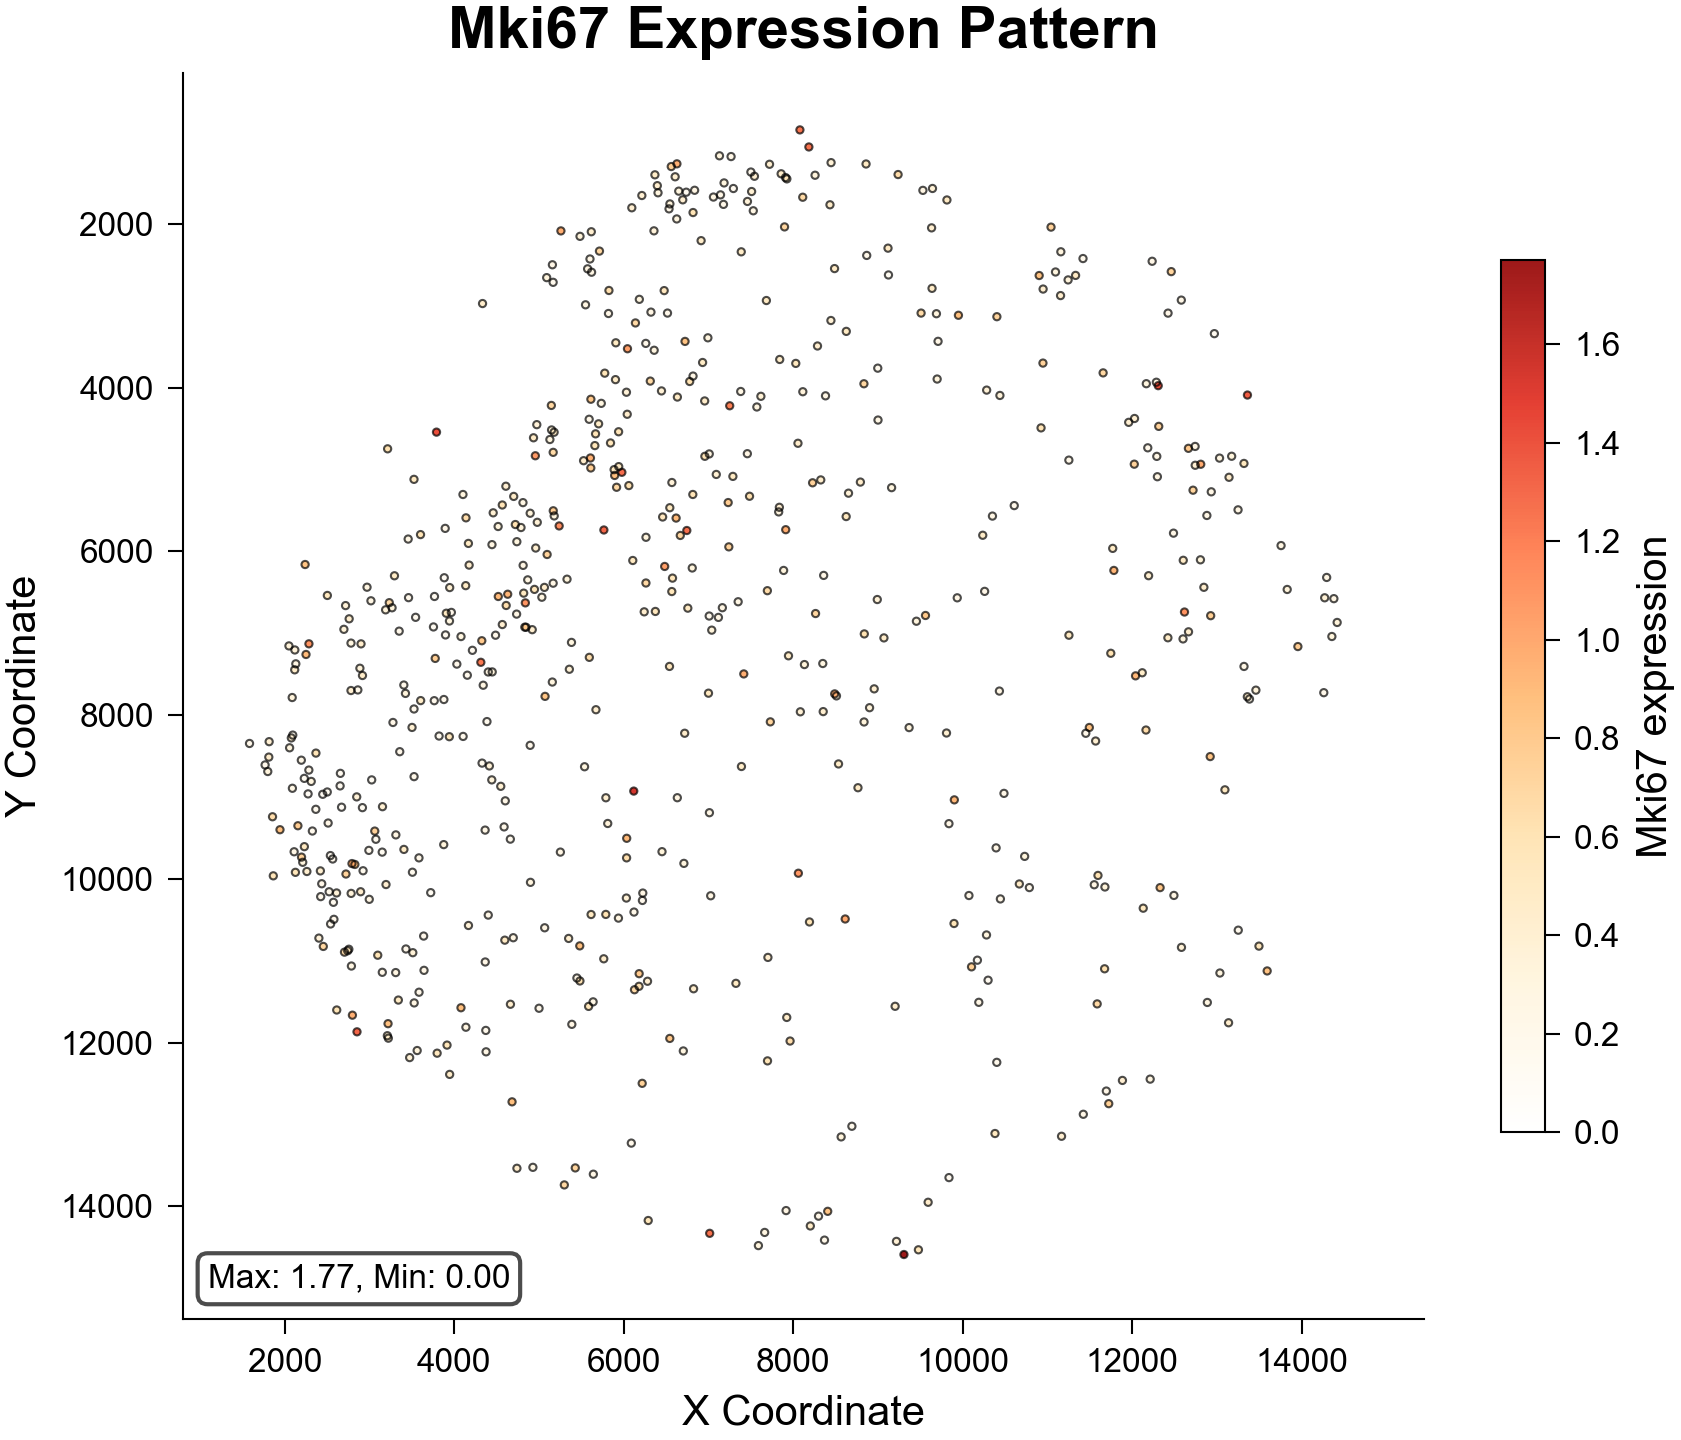

Saved to gene_plots/Mki67_enhanced.pdf


In [32]:
# Plot enhanced expression maps for target genes
print("\nPlotting gene expression maps...")
for gene in target_genes:
    if gene in gene_expr.index:
        plot_gene_expression_enhanced(gene, centroids_filtered, gene_expr_filtered, 
                                     cmap_name="fire")